In [24]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version: ", tf.__version__)
print("Gpu: ", "Available" if tf.config.list_physical_devices('GPU') else "Not Available")

TensorFlow version:  2.21.0
Gpu:  Not Available


In [25]:
keras.backend.clear_session()
vgg_model = keras.Sequential(name="mini_vgg")
vgg_model.add(keras.Input(shape=(128, 128, 3)))
vgg_model.add(layers.Rescaling(1./255))
vgg_model.summary()

Model: "mini_vgg"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [26]:
vgg_model.add(layers.Conv2D(32, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
vgg_model.add(layers.BatchNormalization())
vgg_model.add(layers.Activation('relu'))
vgg_model.add(layers.Conv2D(32, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
vgg_model.add(layers.BatchNormalization())
vgg_model.add(layers.Activation('relu'))
vgg_model.add(layers.MaxPool2D(pool_size=(2, 2)))
vgg_model.summary()

Model: "mini_vgg"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,336 (40.38 KB)

 Trainable params: 10,208 (39.88 KB)

 Non-trainable params: 128 (512.00 B)

In [27]:
vgg_model.add(layers.Conv2D(64, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
vgg_model.add(layers.BatchNormalization())
vgg_model.add(layers.Activation('relu'))
vgg_model.add(layers.Conv2D(64, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
vgg_model.add(layers.BatchNormalization())
vgg_model.add(layers.Activation('relu'))
vgg_model.add(layers.MaxPool2D(pool_size=(2, 2)))
vgg_model.summary()

Model: "mini_vgg"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,144 (258.38 KB)

 Trainable params: 65,760 (256.88 KB)

 Non-trainable params: 384 (1.50 KB)

In [28]:
vgg_model.add(layers.Conv2D(128, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
vgg_model.add(layers.BatchNormalization())
vgg_model.add(layers.Activation('relu'))
vgg_model.add(layers.Conv2D(128, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
vgg_model.add(layers.BatchNormalization())
vgg_model.add(layers.Activation('relu'))
vgg_model.add(layers.MaxPool2D(pool_size=(2, 2)))
vgg_model.summary()

Model: "mini_vgg"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             

 Total params: 288,352 (1.10 MB)

 Trainable params: 287,456 (1.10 MB)

 Non-trainable params: 896 (3.50 KB)

In [29]:
vgg_model.add(layers.Conv2D(256, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
vgg_model.add(layers.BatchNormalization())
vgg_model.add(layers.Activation('relu'))
vgg_model.add(layers.Conv2D(256, kernel_size=(3, 3), use_bias=False, padding='same', kernel_initializer='he_normal'))
vgg_model.add(layers.BatchNormalization())
vgg_model.add(layers.Activation('relu'))
vgg_model.add(layers.MaxPool2D(pool_size=(2, 2)))
vgg_model.add(layers.GlobalAveragePooling2D())
vgg_model.add(layers.Dense(256, activation='relu', kernel_initializer='he_normal'))
vgg_model.add(layers.Dropout(0.5))
vgg_model.add(layers.Dense(1, activation='sigmoid', kernel_initializer='he_normal'))
vgg_model.summary()

Model: "mini_vgg"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             

 Total params: 1,241,185 (4.73 MB)

 Trainable params: 1,239,265 (4.73 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [30]:
opt = keras.optimizers.Adam(learning_rate=0.001)
vgg_model.compile(
    optimizer=opt,
    loss='binary_crossentropy',
    metrics=['accuracy',
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')]
)

In [33]:


train_ds = tf.keras.utils.image_dataset_from_directory(
  "Big_Dataset",
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(128,128),
  batch_size=16)

val_ds = tf.keras.utils.image_dataset_from_directory(
  "Big_Dataset",
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(128,128),
  batch_size=16)




Found 1952 files belonging to 2 classes.
Using 1562 files for training.
Found 1952 files belonging to 2 classes.
Using 390 files for validation.


In [ ]:
import tensorflow as tf
"""
Params:

Random rotaion: rotates by a random amount in the range(-0.03*2pi, 0.03*2pi)
Random zoom: zooms by a random small amount
Random Translation: translates the image by a random small amount

each has a seed to run the same was each time for the purpose of reproducable results

"""

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03,seed=123),
    tf.keras.layers.RandomZoom(0.1,seed=123),
    tf.keras.layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,seed=123
    )
])#rotates zooms and shifts pixels in the images randomly to reduce overfitting

train_ds_augmented = train_ds.map(
    lambda images, labels: (
        data_augmentation(images, training=True),
        labels
    )
)#maps this augmentation onto the images in train_ds (not val_ds as no need to augment validation images)
"""
Params:
training dataset : dataset we are training on
epochs : amount of full runs through the model
validation data : data is held back in the model and used at the end to check for over fitting
verbose : gives a progress bar (helpful for us for testing)
"""
history = vgg_model.fit(
    train_ds_augmented,
    epochs=30,
    validation_data=val_ds,
    verbose=1
)
#runs our training images through the model and validates them at the end 

TypeError: TensorFlowTrainer.fit() got an unexpected keyword argument 'seed'

In [ ]:
"""class_names = train_ds.class_names
print(class_names)

history = vgg_model.fit(train_ds, epochs=30,validation_data=val_ds, verbose=1)
"""

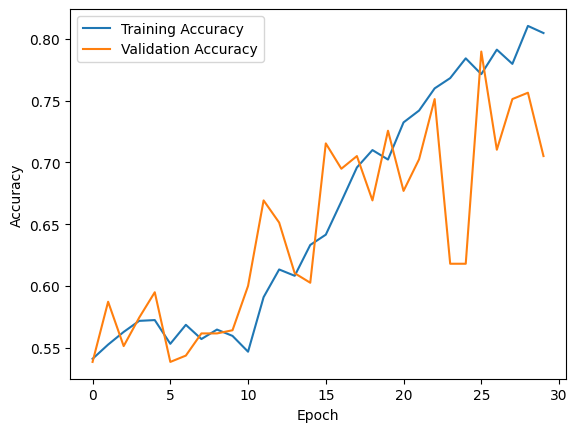

In [36]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

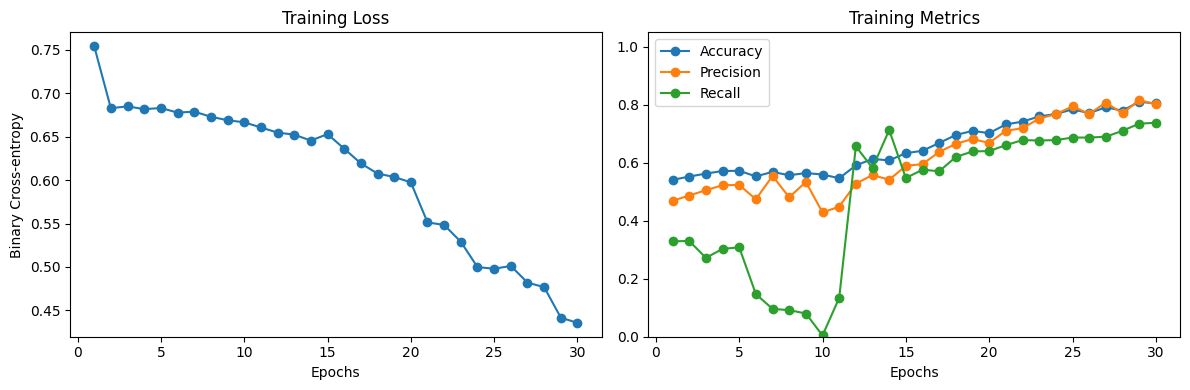

In [ ]:
import matplotlib.pyplot as plt

epoch_range = range(1, len(history.history['loss']) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epoch_range, history.history['loss'], marker='o')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Binary Cross-entropy')

plt.subplot(1, 2, 2)
plt.plot(epoch_range, history.history['accuracy'], marker='o', label='Accuracy')
plt.plot(epoch_range, history.history['precision'], marker='o', label='Precision')
plt.plot(epoch_range, history.history['recall'], marker='o', label='Recall')
plt.title('Training Metrics')
plt.xlabel('Epochs')
plt.ylim(0, 1.05)
plt.legend()

plt.tight_layout()
plt.show()